# 01 — Czyszczenie danych

**Cel:** przygotować czysty zbiór ofert najmu mieszkań w Warszawie do dalszej analizy.

Kroki:
1. Wczytanie wszystkich miesięcznych plików z ofertami najmu
2. Wybór ofert z Warszawy
3. Przegląd danych i braków
4. Porządkowanie kolumn i typów
5. Duplikaty — jedna oferta występuje w wielu miesiącach
6. Wartości odstające
7. Nowe cechy (cena za m², wiek budynku, kategoria piętra)
8. Zapis danych do `data/processed/`

In [2]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"

## 1. Wczytanie danych

Każdy plik `apartments_rent_pl_RRRR_MM.csv` to migawka ofert z jednego miesiąca.
Łączymy je w jedną tabelę i dodajemy kolumnę `month` z datą migawki (wziętą z nazwy pliku).

In [3]:
files = sorted(glob.glob(f"{RAW_DIR}/apartments_rent_pl_*.csv"))

frames = []
for path in files:
    month = os.path.basename(path)[-11:-4]          # np. "2023_11"
    frame = pd.read_csv(path)
    frame["month"] = pd.to_datetime(month, format="%Y_%m")
    frames.append(frame)

df_all = pd.concat(frames, ignore_index=True)
print(f"Plików: {len(files)}, wierszy: {len(df_all):,}")
df_all.head()

Plików: 8, wierszy: 70,847


,id,city,type,squareMeters,rooms,floor,floorCount,buildYear,latitude,longitude,centreDistance,poiCount,schoolDistance,clinicDistance,postOfficeDistance,kindergartenDistance,restaurantDistance,collegeDistance,pharmacyDistance,ownership,buildingMaterial,condition,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom,price,month
0,2a1a6db97ff122d6bc148abb6f0e498a,szczecin,blockOfFlats,52.0,2.0,3.0,3.0,2008.0,53.460535,14.545416,4.26,2.0,0.753,1.049,0.595,0.674,0.229,2.200,0.307,condominium,brick,NaN,yes,yes,no,no,no,3500,2023-11-01
1,5a0cb42c088eadf75aa98a4118640048,szczecin,blockOfFlats,57.0,3.0,NaN,10.0,1976.0,53.440955,14.566024,1.98,14.0,0.126,0.875,0.586,0.058,0.129,1.323,0.189,condominium,NaN,premium,no,yes,yes,no,no,3000,2023-11-01
2,996722490efcb4b34d48bb84a9a72838,szczecin,NaN,43.4,2.0,3.0,4.0,NaN,53.435746,14.560764,1.37,17.0,0.265,0.373,0.385,0.364,0.116,0.714,0.211,condominium,NaN,NaN,no,yes,no,no,no,1900,2023-11-01
3,50d75c688530b9a61ba505301e0b94a9,szczecin,apartmentBuilding,32.6,2.0,5.0,6.0,2021.0,53.421582,14.541572,1.30,16.0,0.081,0.565,0.223,0.482,0.151,0.689,0.192,condominium,brick,premium,no,yes,yes,no,no,2500,2023-11-01
4,9b187f4203adabf466fd08610d8f4e5e,szczecin,apartmentBuilding,72.0,3.0,6.0,6.0,2014.0,53.450010,14.547230,3.10,11.0,0.313,1.065,0.331,0.234,0.496,1.387,0.315,condominium,brick,premium,no,yes,yes,no,yes,2999,2023-11-01


## 2. Oferty z Warszawy

In [4]:
print(df_all["city"].value_counts())

df = df_all[df_all["city"] == "warszawa"].copy()
print(f"\nWarszawa: {len(df):,} wierszy, {df['id'].nunique():,} unikalnych ofert")

city
warszawa       28414
krakow         12661
wroclaw         6676
lodz            5214
poznan          3890
gdansk          3595
katowice        2669
gdynia          1483
szczecin        1482
bydgoszcz       1478
lublin          1313
czestochowa      661
rzeszow          614
bialystok        440
radom            257
Name: count, dtype: int64

Warszawa: 28,414 wierszy, 14,785 unikalnych ofert


## 3. Przegląd danych

Sprawdzamy typy kolumn, podstawowe statystyki i odsetek braków.

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 28414 entries, 4660 to 70632
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    28414 non-null  str           
 1   city                  28414 non-null  str           
 2   type                  20549 non-null  str           
 3   squareMeters          28414 non-null  float64       
 4   rooms                 28414 non-null  float64       
 5   floor                 25407 non-null  float64       
 6   floorCount            28003 non-null  float64       
 7   buildYear             21801 non-null  float64       
 8   latitude              28414 non-null  float64       
 9   longitude             28414 non-null  float64       
 10  centreDistance        28414 non-null  float64       
 11  poiCount              28414 non-null  float64       
 12  schoolDistance        28408 non-null  float64       
 13  clinicDistance        28407 n

In [6]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
squareMeters,28414.0,62.362356,25.0,42.8,54.0,75.0,150.0,26.908172
rooms,28414.0,2.587246,1.0,2.0,2.0,3.0,6.0,0.964678
floor,25407.0,3.848034,1.0,2.0,3.0,5.0,27.0,2.948509
floorCount,28003.0,6.481127,1.0,4.0,6.0,8.0,30.0,3.742205
buildYear,21801.0,1994.082152,1860.0,1975.0,2006.0,2016.0,2024.0,30.244693
latitude,28414.0,52.220518,52.09534,52.193889,52.225769,52.242072,52.36201,0.038832
longitude,28414.0,21.008189,20.858196,20.980323,21.010421,21.03929,21.246734,0.050184
centreDistance,28414.0,4.820703,0.06,2.4,4.44,6.6,16.62,2.955759
poiCount,28414.0,29.08531,0.0,13.0,21.0,35.0,131.0,25.235055
schoolDistance,28408.0,0.318993,0.005,0.163,0.259,0.402,2.489,0.234565


In [7]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0].to_frame("% braków")

,% braków
condition,78.4
buildingMaterial,39.7
type,27.7
buildYear,23.3
floor,10.6
hasElevator,4.0
floorCount,1.4
collegeDistance,0.9
restaurantDistance,0.3
kindergartenDistance,0.1


**Obserwacje:**
- `condition` (stan mieszkania) — ok. 78% braków, kolumna jest praktycznie bezużyteczna → usuwamy.
- `buildingMaterial` (~40%), `type` (~28%), `buildYear` (~23%) — dużo braków, ale to ważne cechy → zostawiamy, braki oznaczamy jako `unknown` (dla kategorii) lub zostawiamy puste (dla roku budowy).
- `floor` (~11%) — braki zostawiamy jako puste.
- Odległości do POI — pojedyncze braki, nie przeszkadzają.

Warto też zauważyć, że dane wyglądają na wstępnie przefiltrowane przez autora zbioru: ceny są w zakresie 2 200–23 000 zł, a powierzchnia 25–150 m².

## 4. Porządkowanie kolumn i typów

In [8]:
# Kolumny stałe lub prawie puste
print("ownership:", df["ownership"].unique())   # tylko 'condominium' — brak informacji
df = df.drop(columns=["city", "ownership", "condition"])

# Kolumny tak/nie -> wartości logiczne (True/False, brak = <NA>)
yes_no_cols = ["hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity", "hasStorageRoom"]
for col in yes_no_cols:
    df[col] = df[col].map({"yes": True, "no": False}).astype("boolean")

# Kategorie: brak -> 'unknown'
for col in ["type", "buildingMaterial"]:
    df[col] = df[col].fillna("unknown")

# Liczby całkowite (z obsługą braków)
for col in ["rooms", "floor", "floorCount", "buildYear", "poiCount"]:
    df[col] = df[col].astype("Int64")

df.dtypes

ownership: <StringArray>
['condominium']
Length: 1, dtype: str


id                                 str
type                               str
squareMeters                   float64
rooms                            Int64
floor                            Int64
floorCount                       Int64
buildYear                        Int64
latitude                       float64
longitude                      float64
centreDistance                 float64
poiCount                         Int64
schoolDistance                 float64
clinicDistance                 float64
postOfficeDistance             float64
kindergartenDistance           float64
restaurantDistance             float64
collegeDistance                float64
pharmacyDistance               float64
buildingMaterial                   str
hasParkingSpace                boolean
hasBalcony                     boolean
hasElevator                    boolean
hasSecurity                    boolean
hasStorageRoom                 boolean
price                            int64
month                   d

## 5. Duplikaty

Ta sama oferta (to samo `id`) pojawia się w kilku miesiącach — jeśli wisiała na portalu np. 3 miesiące, jest w 3 plikach.
Gdybyśmy liczyli średnie na wszystkich wierszach, oferty „długo wiszące” miałyby większą wagę.

Dlatego tworzymy **dwie tabele**:
- `monthly` — wszystkie wiersze (oferta × miesiąc) → do analizy zmian w czasie,
- `listings` — **jedna oferta = jeden wiersz** (ostatnia znana wersja) → do większości analiz.

Duplikaty id w tym samym miesiącu: 0


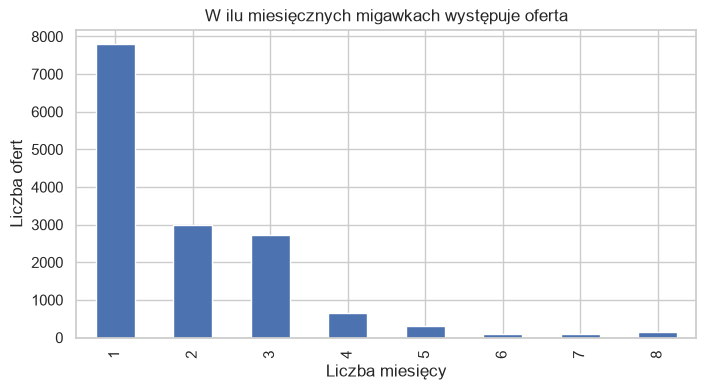

In [9]:
# Czy w jednym miesiącu ta sama oferta występuje dwa razy?
print("Duplikaty id w tym samym miesiącu:", df.duplicated(["id", "month"]).sum())

months_per_offer = df.groupby("id")["month"].nunique()
months_per_offer.value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.title("W ilu miesięcznych migawkach występuje oferta")
plt.xlabel("Liczba miesięcy")
plt.ylabel("Liczba ofert")
plt.show()

In [10]:
df = df.sort_values(["id", "month"])

# Historia każdej oferty: pierwsza/ostatnia migawka i zmiana ceny
history = df.groupby("id").agg(
    first_seen=("month", "min"),
    last_seen=("month", "max"),
    months_listed=("month", "nunique"),
    first_price=("price", "first"),
)

# Ostatnia znana wersja każdej oferty
listings = df.groupby("id").tail(1).set_index("id").join(history).reset_index()
listings["price_change_pct"] = ((listings["price"] / listings["first_price"] - 1) * 100).round(1)

print(f"Ofert: {len(listings):,}")
print(f"Ofert ze zmianą ceny: {(listings['price_change_pct'] != 0).sum():,}")
listings[["id", "price", "first_price", "price_change_pct", "first_seen", "last_seen", "months_listed"]].head()

Ofert: 14,785
Ofert ze zmianą ceny: 1,690


,id,price,first_price,price_change_pct,first_seen,last_seen,months_listed
0,00001188ba46ff840500019be4bbe46d,4100,4100,0.0,2024-06-01,2024-06-01,1
1,000037fc7716df778743ece8c3b16142,3500,3500,0.0,2024-05-01,2024-06-01,2
2,00046165fd78ed4f5468013bf127adc7,3800,3800,0.0,2023-12-01,2024-01-01,2
3,00054446da0e76217d0b441092ca290c,7800,7800,0.0,2024-04-01,2024-05-01,2
4,00066699aff8728875255cce06dba7b6,3000,3000,0.0,2024-06-01,2024-06-01,1


## 6. Wartości odstające

Najlepiej oceniać je na **cenie za m²** — sama cena zależy od wielkości mieszkania.

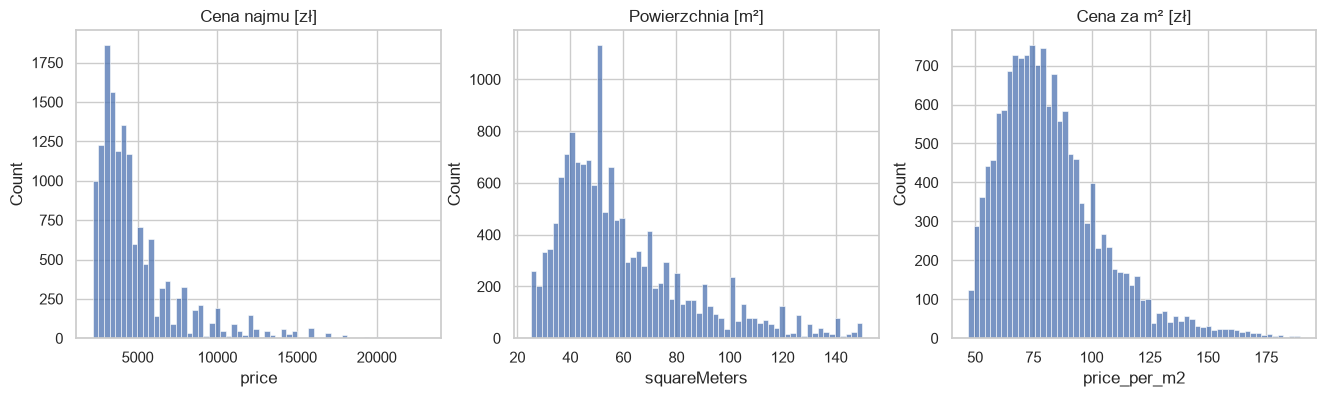

count    14785.0
mean        82.8
std         22.7
min         47.1
1%          50.0
5%          54.0
50%         78.7
95%        125.6
99%        159.4
max        189.5
Name: price_per_m2, dtype: float64

In [11]:
listings["price_per_m2"] = (listings["price"] / listings["squareMeters"]).round(2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(listings["price"], bins=60, ax=axes[0]).set_title("Cena najmu [zł]")
sns.histplot(listings["squareMeters"], bins=60, ax=axes[1]).set_title("Powierzchnia [m²]")
sns.histplot(listings["price_per_m2"], bins=60, ax=axes[2]).set_title("Cena za m² [zł]")
plt.show()

listings["price_per_m2"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1)

Rozkład ceny za m² ma długi prawy ogon. Usuwamy skrajne 1% z każdej strony (poniżej 1. i powyżej 99. percentyla) —
to głównie oferty nietypowe (luksusowe apartamenty, błędnie wpisana powierzchnia itp.).

In [12]:
low, high = listings["price_per_m2"].quantile([0.01, 0.99])
outliers = ~listings["price_per_m2"].between(low, high)

print(f"Granice: {low:.1f} – {high:.1f} zł/m²")
print(f"Usuwamy {outliers.sum()} ofert ({outliers.mean():.1%})")

listings = listings[~outliers].copy()
monthly = df[df["id"].isin(listings["id"])].copy()

Granice: 50.0 – 159.4 zł/m²
Usuwamy 289 ofert (2.0%)


## 7. Nowe cechy

- `price_per_m2` — cena za m² (już policzona)
- `building_age` — wiek budynku w 2024 r.
- `is_new_building` — budynek z 2015 r. lub nowszy
- `floor_category` — parter/niskie, środkowe, wysokie, ostatnie piętro
- `building_height` — niski (do 4 pięter), średni (5–10), wysoki (11+)

In [13]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["price_per_m2"] = (data["price"] / data["squareMeters"]).round(2)
    data["building_age"] = 2024 - data["buildYear"]
    data["is_new_building"] = (data["buildYear"] >= 2015).astype("boolean")

    floor_cat = pd.Series("środkowe", index=data.index)
    floor_cat[data["floor"] <= 1] = "parter/1. piętro"
    floor_cat[data["floor"] >= 10] = "wysokie (10+)"
    floor_cat[(data["floor"] == data["floorCount"]) & (data["floorCount"] > 1)] = "ostatnie"
    floor_cat[data["floor"].isna()] = "unknown"
    data["floor_category"] = floor_cat

    data["building_height"] = pd.cut(
        data["floorCount"].astype("float"),
        bins=[0, 4, 10, np.inf],
        labels=["niski (do 4)", "średni (5–10)", "wysoki (11+)"],
    )
    return data

listings = add_features(listings)
monthly = add_features(monthly)

listings[["price", "squareMeters", "price_per_m2", "buildYear", "building_age",
          "is_new_building", "floor", "floorCount", "floor_category", "building_height"]].head(10)

,price,squareMeters,price_per_m2,buildYear,building_age,is_new_building,floor,floorCount,floor_category,building_height
0,4100,46.0,89.13,<NA>,<NA>,<NA>,1,8,parter/1. piętro,średni (5–10)
1,3500,50.0,70.00,1975,49,False,4,4,ostatnie,niski (do 4)
2,3800,70.0,54.29,1980,44,False,3,10,środkowe,średni (5–10)
3,7800,130.0,60.00,2002,22,False,7,8,środkowe,średni (5–10)
4,3000,40.0,75.00,<NA>,<NA>,<NA>,<NA>,3,unknown,niski (do 4)
5,8500,110.0,77.27,2015,9,True,3,4,środkowe,niski (do 4)
6,3000,46.0,65.22,1980,44,False,3,7,środkowe,średni (5–10)
7,3500,64.0,54.69,1976,48,False,10,13,wysokie (10+),wysoki (11+)
8,4800,65.0,73.85,<NA>,<NA>,<NA>,1,3,parter/1. piętro,niski (do 4)
9,4000,48.4,82.64,2010,14,False,2,5,środkowe,średni (5–10)


## 8. Zapis danych

In [14]:
os.makedirs(PROCESSED_DIR, exist_ok=True)

listings.to_csv(f"{PROCESSED_DIR}/warsaw_rent_listings.csv", index=False)
monthly.to_csv(f"{PROCESSED_DIR}/warsaw_rent_monthly.csv", index=False)

print(f"listings: {listings.shape[0]:,} wierszy, {listings.shape[1]} kolumn")
print(f"monthly:  {monthly.shape[0]:,} wierszy, {monthly.shape[1]} kolumn")

listings: 14,496 wierszy, 36 kolumn
monthly:  27,877 wierszy, 31 kolumn


## Podsumowanie

- Z ok. 28 tys. wierszy dla Warszawy powstało ok. 14,5 tys. **unikalnych ofert** (`warsaw_rent_listings.csv`).
- Zachowano też historię miesięczną (`warsaw_rent_monthly.csv`) do analizy zmian w czasie.
- Usunięto kolumny bez wartości informacyjnej (`city`, `ownership`, `condition`) oraz 2% skrajnych ofert.
- Dodano cechy: cena za m², wiek budynku, nowe budownictwo, kategoria piętra, wysokość budynku.

**Następny krok:** przypisanie dzielnic na podstawie współrzędnych i odległość do najbliższej stacji metra.